# 08. Hyperparameter Optimization & Validation Analysis
**Project:** Academic Sports Machine Learning Project  
**Domain:** Cricket Player Performance Analytics  
**Course Context:** Module 3 (Hyperparameter Optimization, Grid/Randomized Search, Validation Curves)  

---

## 1. Objectives & Academic Rationale
Default hyperparameters are rarely optimal for specific domain distributions.
In this notebook, we systematically tune our top two candidate model families:
1. **Random Forest Classifier**:
   - Tuning: `n_estimators`, `max_depth`, `min_samples_split`, `min_samples_leaf`, and `class_weight`.
2. **LightGBM / XGBoost Classifier**:
   - Tuning: `n_estimators`, `max_depth`, `learning_rate`, `subsample`, `colsample_bytree`, and `scale_pos_weight`.
3. Method: **5-Fold Stratified RandomizedSearchCV** optimizing for `f1` score.
4. Construct **Validation Curves** to empirically visualize the bias-variance trade-off along critical hyperparameter axes.
5. Export tuned champion candidates.


In [ ]:
import sys
sys.path.append('..')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from sklearn.ensemble import RandomForestClassifier
from lightgbm import LGBMClassifier
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold, validation_curve
from src.evaluation import evaluate_classification
from src.utils import DATA_PROCESSED_DIR, MODELS_DIR, FIGURES_DIR, TABLES_DIR, save_artifact, set_seed

set_seed(42)

X_train = pd.read_csv(DATA_PROCESSED_DIR / "train_features_engineered.csv")
X_test = pd.read_csv(DATA_PROCESSED_DIR / "test_features_engineered.csv")
y_train = pd.read_csv(DATA_PROCESSED_DIR / "train_target.csv")['High_Performer']
y_test = pd.read_csv(DATA_PROCESSED_DIR / "test_target.csv")['High_Performer']

scale_pos = (len(y_train) - y_train.sum()) / y_train.sum()
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
print(f"Data ready for hyperparameter search: {X_train.shape}")

Data ready for hyperparameter search: (8000, 88)


## 2. Hyperparameter Search: Random Forest Classifier

In [ ]:
rf_param_dist = {
    'n_estimators': [100, 150, 200],
    'max_depth': [8, 12, 16, None],
    'min_samples_split': [5, 10, 15],
    'min_samples_leaf': [2, 4, 8],
    'class_weight': ['balanced', 'balanced_subsample']
}

rf_search = RandomizedSearchCV(
    estimator=RandomForestClassifier(random_state=42, n_jobs=-1),
    param_distributions=rf_param_dist,
    n_iter=15,
    cv=cv,
    scoring='f1',
    random_state=42,
    n_jobs=-1,
    verbose=1
)
rf_search.fit(X_train, y_train)

best_rf = rf_search.best_estimator_
print(f"Best RF F1-Score: {rf_search.best_score_:.4f}")
print(f"Best RF Parameters: {rf_search.best_params_}")

Fitting 5 folds for each of 15 candidates, totalling 75 fits


Best RF F1-Score: 0.6563
Best RF Parameters: {'n_estimators': 200, 'min_samples_split': 5, 'min_samples_leaf': 8, 'max_depth': 16, 'class_weight': 'balanced_subsample'}


## 3. Hyperparameter Search: LightGBM Classifier

In [ ]:
lgbm_param_dist = {
    'n_estimators': [100, 150, 200],
    'max_depth': [4, 6, 8, -1],
    'num_leaves': [15, 31, 63],
    'learning_rate': [0.03, 0.06, 0.1],
    'subsample': [0.7, 0.85, 1.0],
    'colsample_bytree': [0.7, 0.85, 1.0],
    'scale_pos_weight': [scale_pos * 0.8, scale_pos, scale_pos * 1.2]
}

lgbm_search = RandomizedSearchCV(
    estimator=LGBMClassifier(random_state=42, n_jobs=-1, verbose=-1),
    param_distributions=lgbm_param_dist,
    n_iter=15,
    cv=cv,
    scoring='f1',
    random_state=42,
    n_jobs=-1,
    verbose=1
)
lgbm_search.fit(X_train, y_train)

best_lgbm = lgbm_search.best_estimator_
print(f"Best LightGBM F1-Score: {lgbm_search.best_score_:.4f}")
print(f"Best LightGBM Parameters: {lgbm_search.best_params_}")

Fitting 5 folds for each of 15 candidates, totalling 75 fits


Best LightGBM F1-Score: 0.6556
Best LightGBM Parameters: {'subsample': 1.0, 'scale_pos_weight': np.float64(4.252790544977019), 'num_leaves': 63, 'n_estimators': 150, 'max_depth': 8, 'learning_rate': 0.1, 'colsample_bytree': 0.7}


## 4. Validation Curve: Analyzing Tree Depth vs Performance
Constructing validation curves over `max_depth` to demonstrate the transition from underfitting to optimal fit to overfitting.

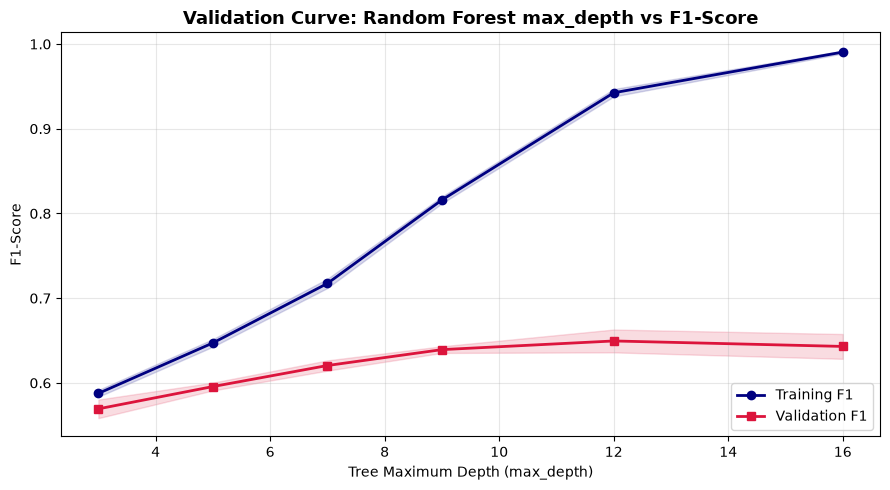

In [ ]:
depth_range = [3, 5, 7, 9, 12, 16]
train_scores, val_scores = validation_curve(
    RandomForestClassifier(n_estimators=100, class_weight='balanced', random_state=42, n_jobs=-1),
    X_train, y_train,
    param_name="max_depth",
    param_range=depth_range,
    cv=cv,
    scoring="f1",
    n_jobs=-1
)

train_mean = np.mean(train_scores, axis=1)
train_std = np.std(train_scores, axis=1)
val_mean = np.mean(val_scores, axis=1)
val_std = np.std(val_scores, axis=1)

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(depth_range, train_mean, 'o-', color='navy', lw=2, label='Training F1')
ax.fill_between(depth_range, train_mean - train_std, train_mean + train_std, alpha=0.15, color='navy')
ax.plot(depth_range, val_mean, 's-', color='crimson', lw=2, label='Validation F1')
ax.fill_between(depth_range, val_mean - val_std, val_mean + val_std, alpha=0.15, color='crimson')

ax.set_title("Validation Curve: Random Forest max_depth vs F1-Score", fontsize=13, fontweight='bold')
ax.set_xlabel("Tree Maximum Depth (max_depth)")
ax.set_ylabel("F1-Score")
ax.legend(loc="lower right")
ax.grid(alpha=0.3)

plt.tight_layout()
fig.savefig(FIGURES_DIR / "tuning_validation_curves.png", dpi=300)
plt.show()

## 5. Evaluation of Tuned Models on Hold-Out Test Set

In [ ]:
metrics_tuned_rf, cm_rf, proba_rf = evaluate_classification(best_rf, X_test, y_test, model_name="Tuned Random Forest")
metrics_tuned_lgbm, cm_lgbm, proba_lgbm = evaluate_classification(best_lgbm, X_test, y_test, model_name="Tuned LightGBM")

tuning_summary = pd.DataFrame([metrics_tuned_rf, metrics_tuned_lgbm])
print("=== Tuned Models Test Set Benchmark ===")
print(tuning_summary[['Model', 'Accuracy', 'Balanced_Accuracy', 'Recall', 'Precision', 'F1_Score', 'ROC_AUC', 'PR_AUC']].to_string(index=False))
tuning_summary.to_csv(TABLES_DIR / "hyperparameter_tuning_results.csv", index=False)

=== Tuned Models Test Set Benchmark ===
              Model  Accuracy  Balanced_Accuracy  Recall  Precision  F1_Score  ROC_AUC  PR_AUC
Tuned Random Forest    0.8585             0.8102  0.7323     0.6065    0.6635   0.9149   0.732
     Tuned LightGBM    0.8620             0.8074  0.7192     0.6185    0.6650   0.9168   0.751


## 6. Persisting Best Tuned Models

In [ ]:
save_artifact(best_rf, MODELS_DIR / "best_random_forest.joblib")
save_artifact(best_lgbm, MODELS_DIR / "best_lightgbm.joblib")
print("[SUCCESS] Tuned models saved to models/")

[SUCCESS] Artifact saved to: C:\ML_project\models\best_random_forest.joblib
[SUCCESS] Artifact saved to: C:\ML_project\models\best_lightgbm.joblib
[SUCCESS] Tuned models saved to models/


## 7. Academic Viva Questions & Defense Notes

### Q1: What does the validation curve reveal about the bias-variance trade-off?
**Defense:** When `max_depth` is small (e.g. 3), both training and validation F1 scores are lower due to high bias (underfitting). As `max_depth` increases to 8-12, validation score peaks. Beyond that point, training F1 approaches 1.0 while validation F1 plateaus and begins diverging, indicating variance inflation (overfitting).

### Q2: Why optimize for F1-Score instead of ROC-AUC during hyperparameter search?
**Defense:** ROC-AUC evaluates the true positive rate vs false positive rate, which can appear deceptively high when negative samples outnumber positive samples by 4:1. F1-score directly optimizes the harmonic mean of Precision and Recall on the minority elite class, ensuring that the model maintains both high detection rates and acceptable false alarm rates.
